In [ ]:
import sys
import pandas as pd
import numpy as np
import os
import importlib
from src.eval_utils import full_evaluation
from src.modeltrainer import *
import matplotlib.pyplot as plt
import glob

# Reimporter les modules pour refléter les modifications
importlib.reload(sys.modules['src.eval_utils'])
importlib.reload(sys.modules['src.modeltrainer'])

sys.path.insert(0, './src')

In [2]:
# =============================================================================
# CELLULE 1 : IMPORT DES DONNÉES
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Chargement des données
print("📂 Chargement des données...")

train_data = pd.read_excel(DATA_PATH, sheet_name='train')
cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Séparation features / target
X_train = train_data.iloc[:, :-1]. drop(columns=COLS_TO_DROP, errors='ignore')
y_train = train_data.iloc[:, -1]

X_cal = cal_data. iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_cal = cal_data.iloc[:, -1]

X_test = test_data.iloc[: , :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print(f"✓ Données chargées:")
print(f"   - Train: {X_train.shape[0]} lignes, {X_train.shape[1]} features")
print(f"   - Calibration: {X_cal.shape[0]} lignes")
print(f"   - Test: {X_test.shape[0]} lignes")
print(f"   - Target distribution (train): {y_train.value_counts().to_dict()}")

📂 Chargement des données...
✓ Données chargées:
   - Train: 83555 lignes, 81 features
   - Calibration: 28381 lignes
   - Test: 28465 lignes
   - Target distribution (train): {0: 46672, 1: 36883}


In [ ]:
# =============================================================================
# CELLULE 2 : CHARGEMENT OU ENTRAÎNEMENT DU MODÈLE
# =============================================================================


# Configuration
MODEL_DIR = 'models'
MODEL_TYPE = 'LogisticRegression'  # 'LogisticRegression', 'RandomForest', 'XGBoost'



# Initialiser le trainer
trainer = ModelML(
    x_train=X_train,
    x_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Chercher un modèle existant
existing_model = find_existing_model(MODEL_DIR, MODEL_TYPE)

if existing_model:
    print(f"📦 Modèle existant trouvé: {existing_model}")
    trainer.load_model(existing_model)
else:
    print(f"🔄 Aucun modèle {MODEL_TYPE} trouvé. Entraînement en cours...")
    
    if MODEL_TYPE == 'LogisticRegression':
        trainer.tune_logistic_regression(
            param_grid={
                'C': [0.01, 0.1, 1, 10],
                'penalty': ['l2'],
                'solver': ['liblinear'],
                'class_weight': [None, 'balanced']
            },
            method='grid',
            cv=5,
            scoring='roc_auc'
        )
    
    elif MODEL_TYPE == 'RandomForest':
        trainer.tune_random_forest(
            param_grid={
                'n_estimators': [50, 100, 200],
                'max_depth': [3, 5, 10, None],
                'min_samples_leaf': [1, 2],
                'max_features': ['sqrt']
            },
            method='random',
            n_iter=20,
            cv=5,
            scoring='roc_auc'
        )
    
    elif MODEL_TYPE == 'XGBoost':
        trainer.tune_xgboost(
            param_grid={
                'n_estimators': [50, 100, 200],
                'max_depth': [3, 5, 7],
                'learning_rate': [0.01, 0.1],
                'subsample': [0.6, 0.8, 1.0]
            },
            method='random',
            n_iter=20,
            cv=5,
            scoring='roc_auc'
        )
    
    trainer.save_model()
    print(f"✓ Modèle entraîné et sauvegardé")

print(f"\n📊 Modèle actif: {trainer.model_name}")
print(f"   Paramètres: {trainer.best_params}")

📦 Modèle existant trouvé: models/logistic_regression_tuned.pkl
✓ Modèle chargé: models/logistic_regression_tuned.pkl
✓ Paramètres chargés: {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}

📊 Modèle actif: logistic_regression_tuned
   Paramètres: {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}



📊 ÉVALUATION SUR LE TRAIN SET

🔍 ÉVALUATION COMPLÈTE:  logistic_regression_tuned_train
📊 MÉTRIQUES D'ÉVALUATION

🎯 Métriques de Classification:
----------------------------------------
   Accuracy                 : 0.7300
   Balanced_Accuracy        : 0.7299
   Precision                : 0.6815
   Recall_Sensitivity       : 0.7291
   Specificity              : 0.7307
   F1_Score                 : 0.7045
   Matthews_Corr_Coef       : 0.4574
   Cohen_Kappa              : 0.4565

📈 Métriques Probabilistes:
----------------------------------------
   ROC_AUC                  : 0.8060
   PR_AUC                   : 0.7571
   Brier_Score              : 0.1799
   Log_Loss                 : 0.5367

📋 RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

    Classe 0       0.77      0.73      0.75     46672
    Classe 1       0.68      0.73      0.70     36883

    accuracy                           0.73     83555
   macro avg       0.73      0.73      0.73     83555


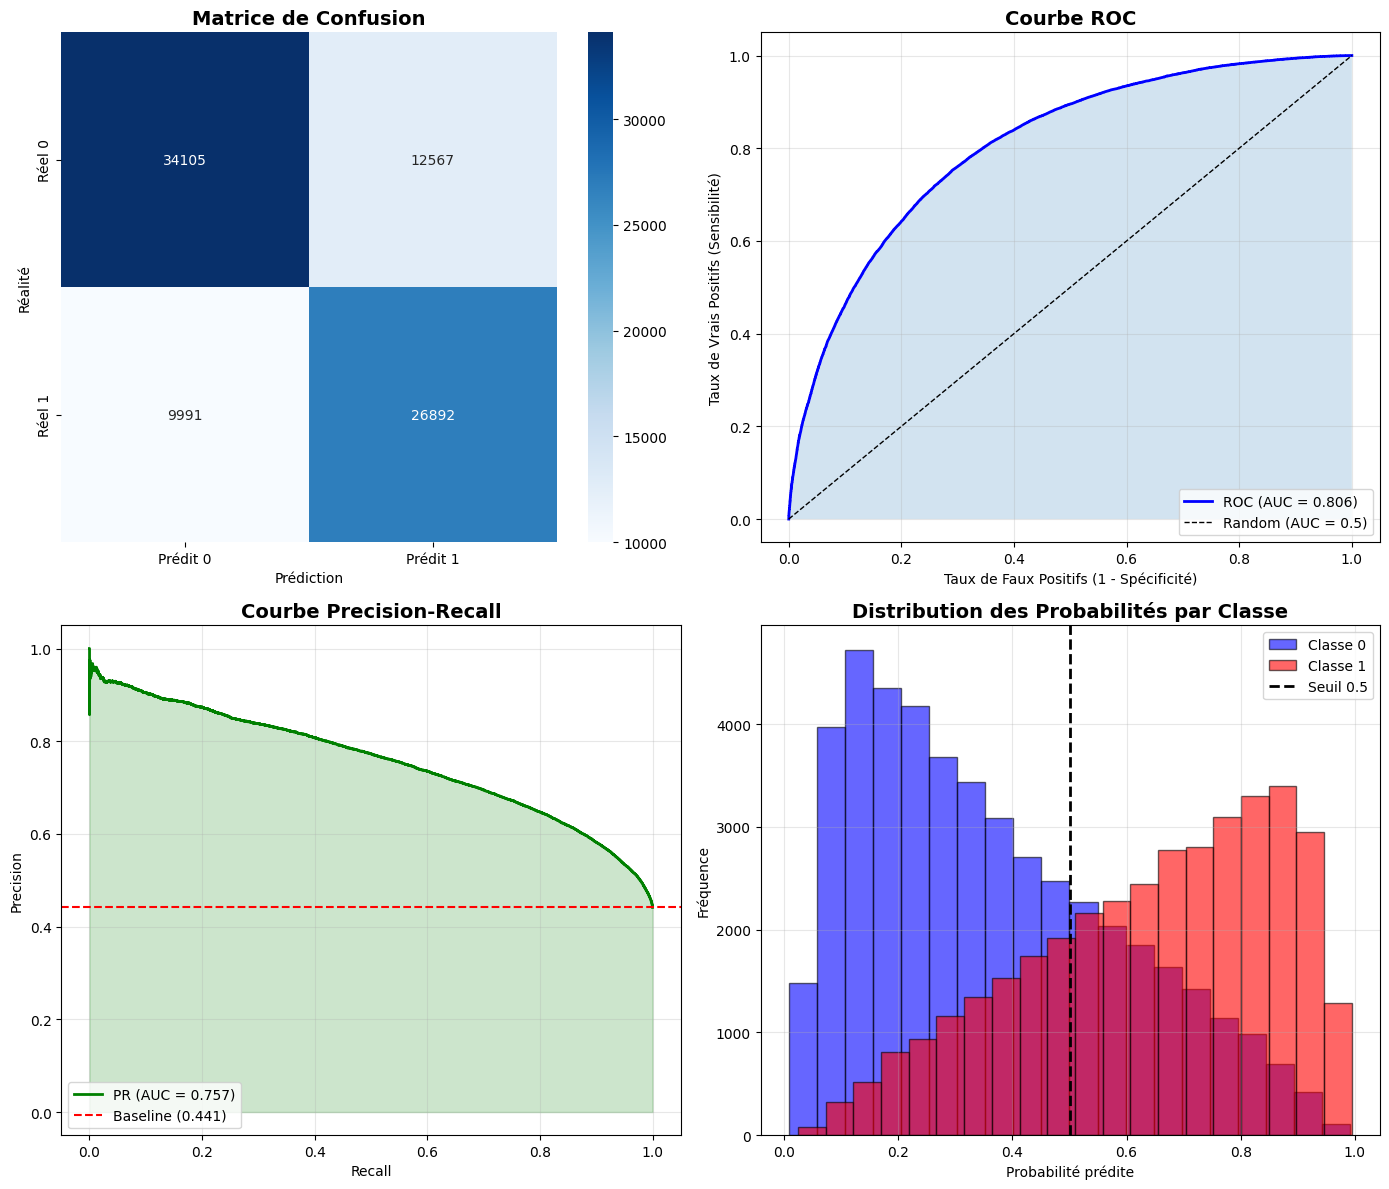

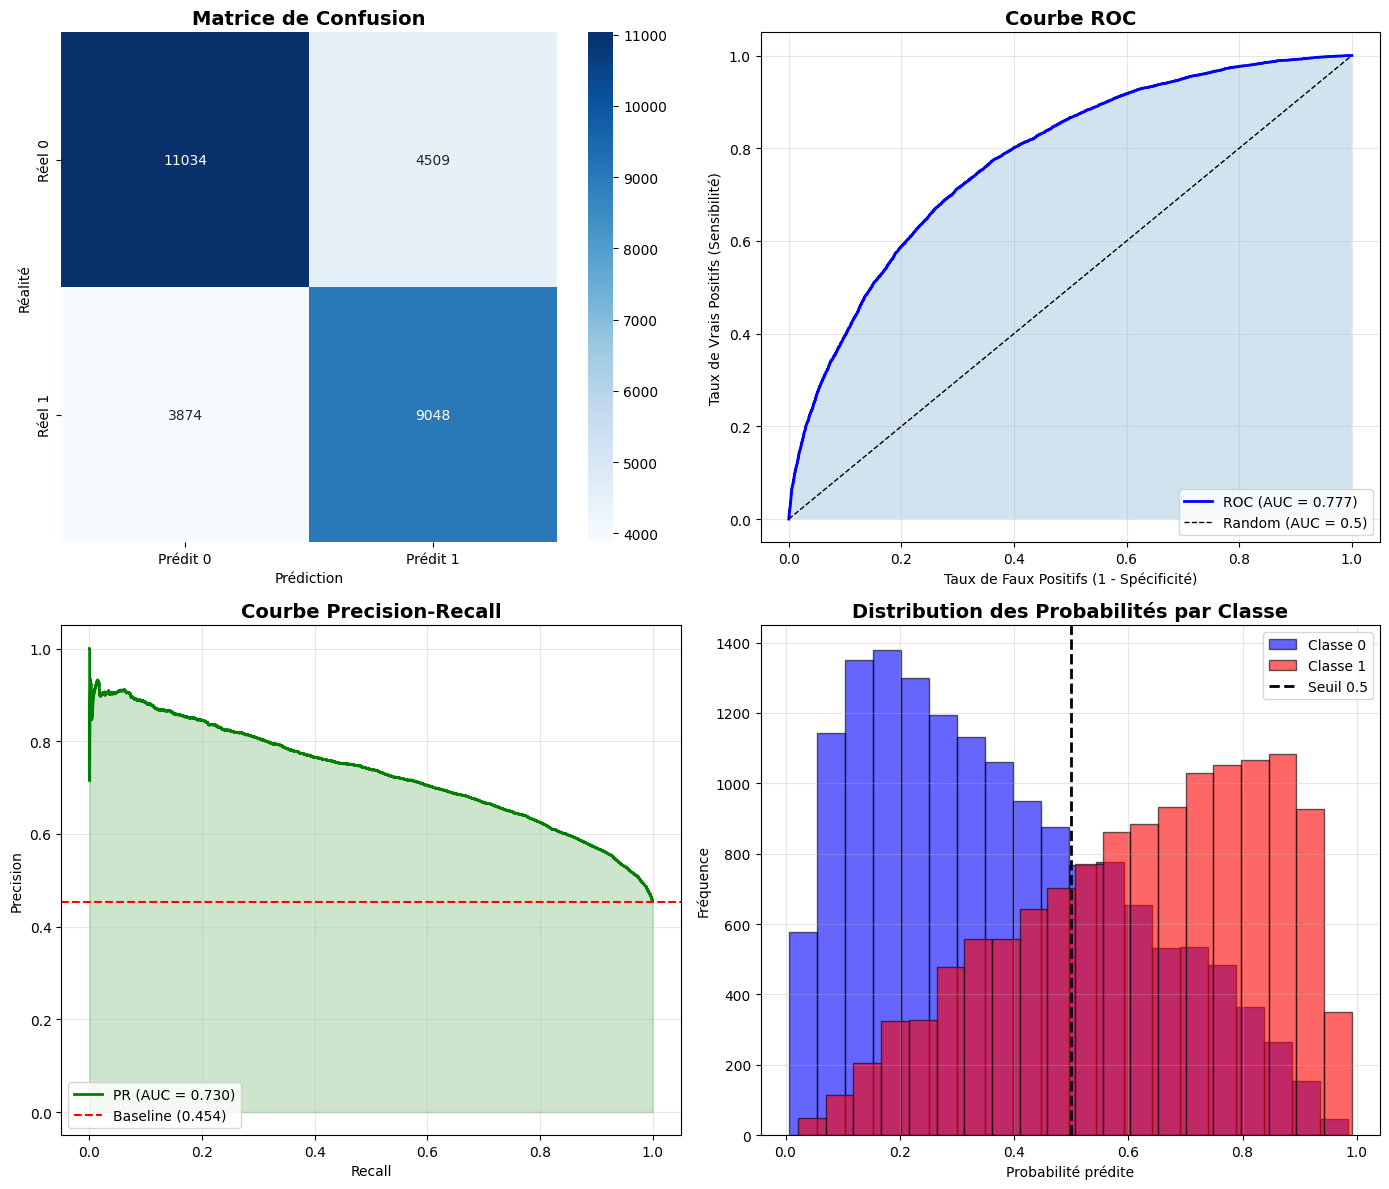


📈 COMPARAISON TRAIN vs TEST
Métrique                         Train         Test         Diff
----------------------------------------------------------------------
Accuracy                        0.7300       0.7055      +0.0245
Balanced_Accuracy               0.7299       0.7051      +0.0249
Precision                       0.6815       0.6674      +0.0141
Recall_Sensitivity              0.7291       0.7002      +0.0289
Specificity                     0.7307       0.7099      +0.0208
F1_Score                        0.7045       0.6834      +0.0211
Matthews_Corr_Coef              0.4574       0.4088      +0.0486
Cohen_Kappa                     0.4565       0.4084      +0.0481
ROC_AUC                         0.8060       0.7768      +0.0292
PR_AUC                          0.7571       0.7305      +0.0266
Brier_Score                     0.1799       0.1927      -0.0128
Log_Loss                        0.5367       0.5675      -0.0308


In [11]:
# =============================================================================
# CELLULE 3 : ÉVALUATION COMPLÈTE SUR LE TRAIN ET TEST SET
# =============================================================================

# --- Évaluation sur le TRAIN SET ---
print("\n" + "="*70)
print("📊 ÉVALUATION SUR LE TRAIN SET")
print("="*70)

y_pred_train = trainer.predict(X_train)
y_proba_train = trainer.predict_proba(X_train)[:, 1]

metrics_train = full_evaluation(
    y_true=y_train,
    y_pred=y_pred_train,
    y_proba=y_proba_train,
    model_name=f"{trainer.model_name}_train",
    save_dir='results'
)

# --- Évaluation sur le TEST SET ---
print("\n" + "="*70)
print("📊 ÉVALUATION SUR LE TEST SET")
print("="*70)

y_pred_test = trainer.predict(X_test)
y_proba_test = trainer.predict_proba(X_test)[:, 1]

metrics_test = full_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=f"{trainer.model_name}_test",
    save_dir='results'
)

# Afficher les plots
plt.show()

# Résumé comparatif
print("\n" + "="*70)
print("📈 COMPARAISON TRAIN vs TEST")
print("="*70)
print(f"{'Métrique':<25} {'Train':>12} {'Test':>12} {'Diff':>12}")
print("-"*70)
for key in metrics_train.keys():
    train_val = metrics_train[key]
    test_val = metrics_test[key]
    diff = train_val - test_val
    print(f"{key:<25} {train_val:>12.4f} {test_val:>12.4f} {diff:>+12.4f}")